# 02 — How SMOTE makes a new fraud

A picture of SMOTE on a tiny made-up 2-D data set, drawn with **our own from-scratch SMOTE**
(`model_build/`), so every new point can be traced back to the two real frauds it came from.
No dataset is needed: the points are made with numpy. The plot is saved as
`artifacts/figures/smote_demo.png`.

**Setup.** Imports, the project seed, and the toy data: 40 legit points around (0, 0) and 8 frauds
around (2, 2). Two numbers per point keep the picture flat; the real data has 29 features, but
SMOTE does exactly the same thing in 29 dimensions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from smote_from_scratch import SMOTE

from fraudstudy.data import PROJECT_ROOT, SEED

FIGURES_DIR = PROJECT_ROOT / "artifacts" / "figures"
rng = np.random.default_rng(SEED)
legit_points = rng.normal(loc=0.0, scale=1.0, size=(40, 2))
fraud_points = rng.normal(loc=2.0, scale=0.8, size=(8, 2))
X = np.vstack([legit_points, fraud_points])
y = np.array([0] * 40 + [1] * 8)
print(f"{len(X)} points: {int((y == 0).sum())} legit, {int((y == 1).sum())} frauds")

48 points: 40 legit, 8 frauds


## 1. Run SMOTE and count the classes
`fit_resample` returns the original rows followed by the new frauds. Our SMOTE always makes as
many new frauds as it takes to match the legit count (in the experiment, imblearn's SMOTE stops
at the ratio the search picks instead). `smote.steps_` records, for every new fraud, its
**parent** (index among the frauds), the **neighbour** it moved towards, and the **gap** (a random
number between 0 and 1).

In [2]:
smote = SMOTE(k_neighbors=5, random_state=SEED)
X_resampled, y_resampled = smote.fit_resample(X, y)
new_points = X_resampled[len(X):]  # the new frauds come after the original rows

print(f"before: {int((y == 0).sum())} legit, {int((y == 1).sum())} frauds")
print(f"after:  {int((y_resampled == 0).sum())} legit, {int((y_resampled == 1).sum())} frauds "
      f"({len(new_points)} new)")
print("first three steps (parent, neighbour, gap):", smote.steps_[:3])

before: 40 legit, 8 frauds
after:  40 legit, 40 frauds (32 new)
first three steps (parent, neighbour, gap): [(0, 4, 0.4388784397520523), (3, 5, 0.6973680290593639), (1, 6, 0.9756223516367559)]


## 2. The picture
Grey dots are legit, filled red dots the real frauds, hollow red circles the new frauds. Each thin
line joins a parent to the neighbour it was paired with: every new fraud lies somewhere on one of
these lines, because SMOTE only ever moves part of the way from one real fraud to another.

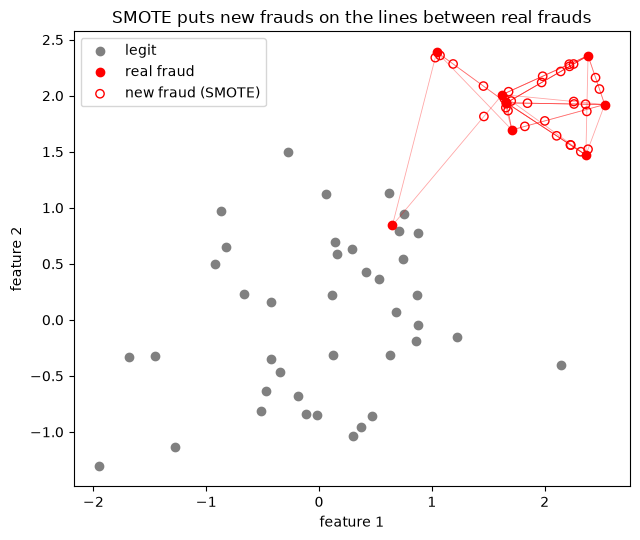

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for parent, neighbour, gap in smote.steps_:
    start, end = fraud_points[parent], fraud_points[neighbour]
    ax.plot([start[0], end[0]], [start[1], end[1]], color="red", linewidth=0.6, alpha=0.35)
ax.scatter(legit_points[:, 0], legit_points[:, 1], color="grey", label="legit")
ax.scatter(fraud_points[:, 0], fraud_points[:, 1], color="red", label="real fraud")
ax.scatter(new_points[:, 0], new_points[:, 1], facecolors="none", edgecolors="red",
           label="new fraud (SMOTE)")
ax.set(title="SMOTE puts new frauds on the lines between real frauds",
       xlabel="feature 1", ylabel="feature 2")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "smote_demo.png", dpi=150)
plt.show()

## 3. One new point worked out by hand
Take the first new fraud. SMOTE's whole rule is one line:
**new point = parent + gap × (neighbour − parent)**. With gap = 0 the new point is the parent,
with gap = 1 it is the neighbour, and in between it is that share of the way along the line.

In [4]:
parent, neighbour, gap = smote.steps_[0]
parent_point, neighbour_point = fraud_points[parent], fraud_points[neighbour]
by_hand = parent_point + gap * (neighbour_point - parent_point)

print(f"parent    (fraud {parent}): {parent_point.round(4)}")
print(f"neighbour (fraud {neighbour}): {neighbour_point.round(4)}")
print(f"gap: {gap:.4f}")
print(f"by hand:   {by_hand.round(4)}")
print(f"SMOTE made: {new_points[0].round(4)}")
print("the same point:", np.allclose(by_hand, new_points[0]))

parent    (fraud 0): [2.3654 1.4705]
neighbour (fraud 4): [2.3846 2.3572]
gap: 0.4389
by hand:   [2.3738 1.8596]
SMOTE made: [2.3738 1.8596]
the same point: True


## What SMOTE assumes, and when it goes wrong
- **It assumes** the space between two nearby frauds is also fraud territory: a payment
  "halfway between" two frauds is treated as a fraud.
- **It goes wrong** when that is false. If two frauds sit on either side of a group of legit
  payments, a new fraud between them lands among legit points. In the picture above, the lowest
  real fraud sits next to legit points, and the lines from it cross empty space where no real
  fraud is; the new frauds placed along them teach the model that this space is fraud. The model
  then flags payments that look legit, which costs precision.
- It only ever copies the patterns the real frauds already have; it cannot invent a new kind
  of fraud, and with very few frauds the neighbours are far apart, so the lines get long.
- That is why the experiment tries several SMOTE ratios and compares SMOTE with the other
  techniques on PR-AUC, instead of assuming it helps.

The step-by-step build of this SMOTE, with every part explained, is in our teammate's notebook
`model_build/src/smote_from_scratch/SMOTE_algo.ipynb`.